<a href="https://colab.research.google.com/github/ejreyesCPE/CPE-031-CPE21S1---Visualizations-and-Data-Analysis---Reyes/blob/main/Hands_On_Activity_9___Exploring_Data_Visually_(REYES_CPE21S1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Hands-On Activity 9 | Exploring Data Visually**





---



Name : Reyes, Eli Justin L.<br>
Course Code and Title : CPE21S1 <br>
Date Submitted : 10/10/26 <br>
Instructor : Engr. Jimlord Quejado


---



**1. Objectives:**

This activity aims to demonstrate students’ ability to visually explore and analyze data using Python. Students will learn how to summarize and visualize categorical, quantitative, time-series, and geospatial data for exploratory data analysis (EDA).

**2. Intended Learning Outcomes (ILOs):**

By the end of this module the students should be able to demonstrate:
1. Analyze various visualization techniques to determine how data representation methods influence understanding, perception, and decision-making.

2. Evaluate existing visualizations in terms of accuracy, clarity, aesthetics, and accessibility, providing justified recommendations for improvement.

3. Create effective, insightful, and user-centered visualizations by integrating appropriate design principles, data encoding techniques, and visualization tools.

**3. Discussions:**

Exploratory Data Analysis (EDA) is the process of analyzing datasets to summarize their main characteristics and gain insights before formal modeling. Visual exploration helps identify trends, relationships, and data quality issues.

Key Components:

Univariate Analysis:
Analyzing one variable at a time (e.g., histograms, bar charts).

Bivariate Analysis:
Exploring relationships between two variables (e.g., scatterplots, crosstabs).

Missing Data Analysis:
Identifying and handling missing or null values.

Time-Series Visualization:
Displaying data across time to reveal trends or seasonality.

Geospatial Visualization:
Mapping data to geographical regions to identify spatial patterns.

EDA is both an art and science combining statistical summaries with visual intuition.

**4. Procedures:**

**Color and Perception**

Section 1: Organizing and Exploring Data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Sample dataset
data = {
    "Product": ["Juice", "Smoothie", "Juice", "Smoothie", "Juice", "Smoothie"],
    "Region": ["North", "South", "East", "West", "North", "East"],
    "Sales": [120, 150, 90, 110, 130, 170],
    "Profit": [30, 45, 20, 25, 35, 50]
}
df = pd.DataFrame(data)

# Display the dataset
df

,Product,Region,Sales,Profit
0,Juice,North,120,30
1,Smoothie,South,150,45
2,Juice,East,90,20
3,Smoothie,West,110,25
4,Juice,North,130,35
5,Smoothie,East,170,50


Task 1: Analyzing Variables One at a Time

/tmp/ipykernel_2365/2975764973.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Region", data=df, palette="Set2")


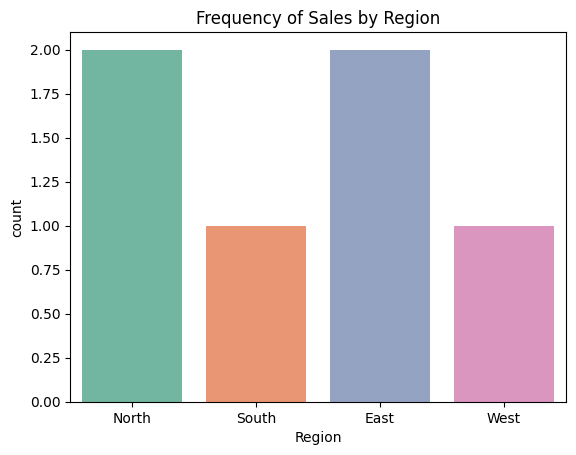

In [ ]:
#Categorical Variable
# Countplot for categorical variable
sns.countplot(x="Region", data=df, palette="Set2")
plt.title("Frequency of Sales by Region")
plt.show()


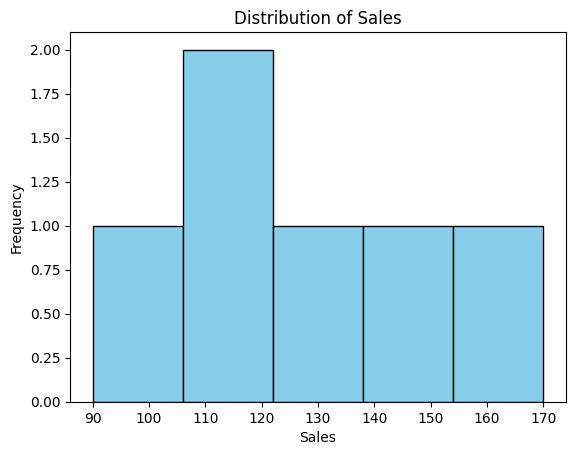

In [ ]:
#Quantitative Variable
# Histogram for quantitative variable
plt.hist(df["Sales"], bins=5, color="skyblue", edgecolor="black")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

Task: <br>
Create one countplot for Product and one histogram for Profit. <br>
Compare their patterns and interpret what they mean.

/tmp/ipykernel_2365/4115969280.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Product", data=df, palette="Set2")


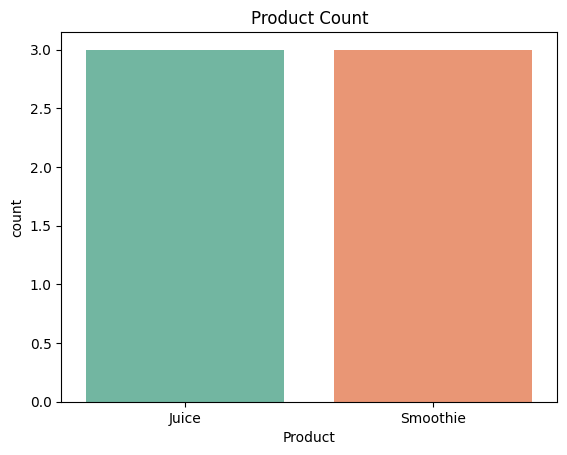

In [ ]:
#Categorical Variable
# Countplot for categorical variable
sns.countplot(x="Product", data=df, palette="Set2")
plt.title("Product Count")
plt.show()

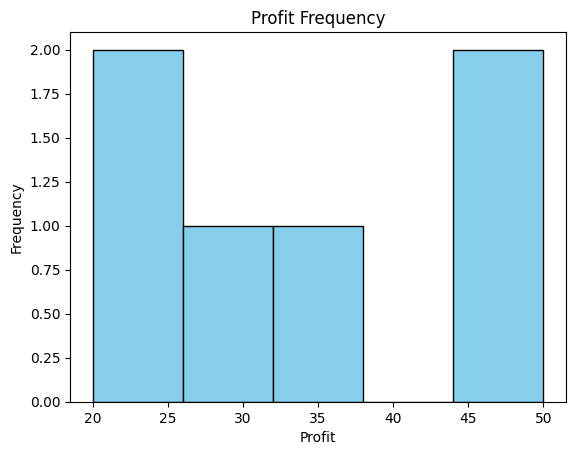

In [ ]:
#Quantitative Variable
# Histogram for quantitative variable
plt.hist(df["Profit"], bins=5, color="skyblue", edgecolor="black")
plt.title("Profit Frequency")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

These two graphs represent the Product Count and Profit Frequency. The Product Count is even considering there are only two products given with even amount of distribution value across the board. The Profit Frequency distribution splits into two clusters because Smoothies yield higher profits (45, 50)while Juices yield lower profits (20, 30, 35), creating a bimodal pattern across a tiny 6-row dataset.   

Section 2: Relationships Between Variables

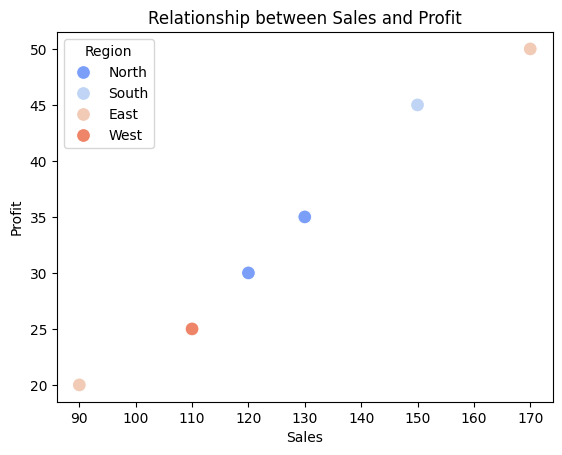

In [ ]:
# Scatterplot: Sales vs Profit
sns.scatterplot(x="Sales", y="Profit", hue="Region", data=df, palette="coolwarm", s=100)
plt.title("Relationship between Sales and Profit")
plt.show()

In [ ]:
# Crosstabulation example
pd.crosstab(df["Region"], df["Product"], values=df["Sales"], aggfunc="mean").fillna(0)


Product,Juice,Smoothie
Region,,
East,90.0,170.0
North,125.0,0.0
South,0.0,150.0
West,0.0,110.0


Task: <br>
Interpret whether higher sales also mean higher profit. <br>
Which region seems to perform best?

Its true that higher sales means higher profit, and the East region performs best with the highest sales and profit.

Section 3: Analysis of Missing Data

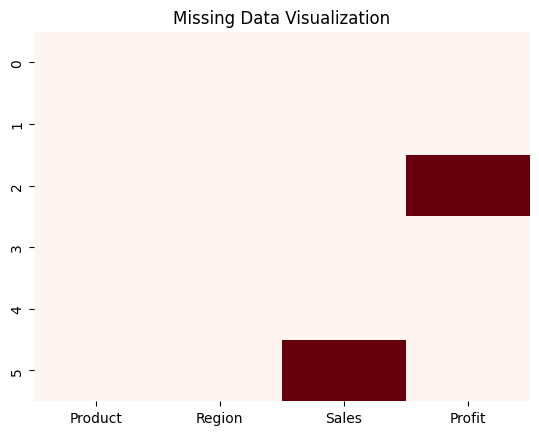

,0
Product,0
Region,0
Sales,1
Profit,1


In [ ]:
# Introduce missing data
df_missing = df.copy()
df_missing.loc[2, "Profit"] = np.nan
df_missing.loc[5, "Sales"] = np.nan

# Visualize missing data
sns.heatmap(df_missing.isnull(), cbar=False, cmap="Reds")
plt.title("Missing Data Visualization")
plt.show()

# Display missing summary
df_missing.isnull().sum()


Task: <br>
Describe what you observe in the missing data visualization. <br>
Which variables need attention before analysis?

The sales and profit variables need attention cause each contains a missing value that needs removal before analysis.

Section 4: Visualizing Time-Series Data

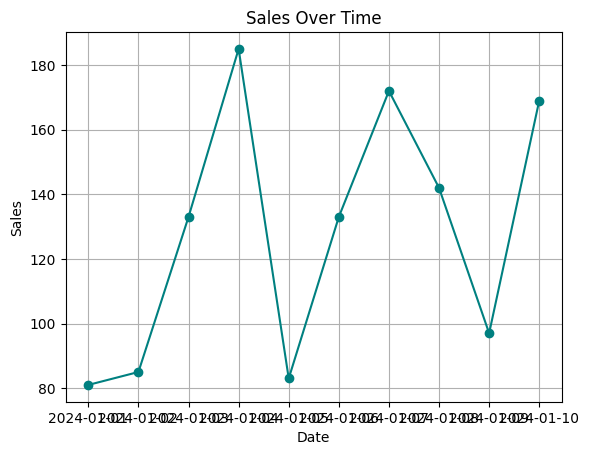

In [ ]:
# Generate time-series example
dates = pd.date_range(start="2024-01-01", periods=10)
sales = np.random.randint(80, 200, 10)
ts_df = pd.DataFrame({"Date": dates, "Sales": sales})

# Line chart for time-series
plt.plot(ts_df["Date"], ts_df["Sales"], marker="o", color="teal")
plt.title("Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

Task: <br>
Add a moving average line (rolling mean) to smooth fluctuations. <br>
Hint: Use ts_df["Sales"].rolling(window=3).mean().

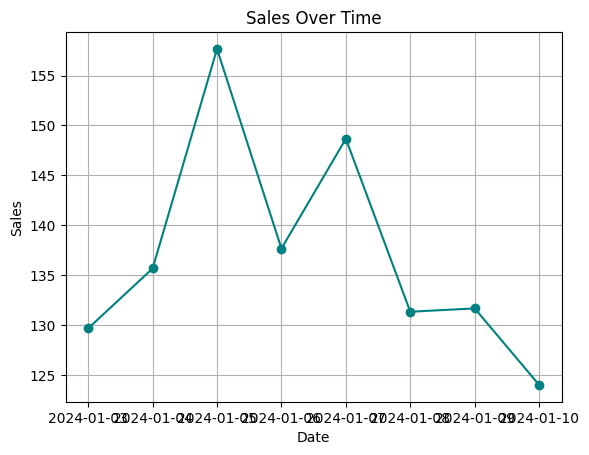

In [ ]:
# Generate time-series example
dates = pd.date_range(start="2024-01-01", periods=10)
sales = np.random.randint(80, 200, 10)
ts_df = pd.DataFrame({"Date": dates, "Sales": sales})

# Line chart for time-series
plt.plot(ts_df["Date"], ts_df["Sales"].rolling(window=3).mean(), marker="o", color="teal")
plt.title("Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

Section 5: Visualizing Geospatial Data

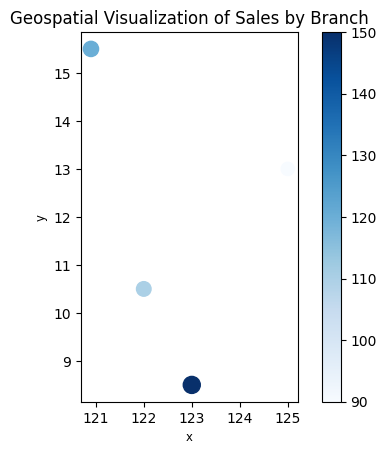

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

# Sample coordinates (latitude, longitude)
coords = {
    "Branch": ["North", "South", "East", "West"],
    "Latitude": [15.5, 8.5, 13.0, 10.5],
    "Longitude": [120.9, 123.0, 125.0, 122.0],
    "Sales": [120, 150, 90, 110]
}

geo_df = pd.DataFrame(coords)
geo_df["geometry"] = [Point(xy) for xy in zip(geo_df.Longitude, geo_df.Latitude)]
gdf = gpd.GeoDataFrame(geo_df, geometry="geometry")

# Plot simple map (Philippines outline optional if available)
gdf.plot(column="Sales", cmap="Blues", legend=True, markersize=geo_df["Sales"])
plt.title("Geospatial Visualization of Sales by Branch")
plt.show()

Task: <br>
Interpret which branch has the highest sales geographically. <br>
How can such visualization help in business decision-making?

The South branch has the highest sales of 150, this visualization helps businesses identify high-performing locations to optimize resource allocation and strategic planning.

**5. Supplementary Activity**

Create your own mini exploratory analysis:

1. Choose a dataset (e.g., from Kaggle, or a CSV file you have).

2. Perform:

*   Univariate analysis (1 categorical + 1 quantitative)
*   Bivariate analysis (scatterplot or crosstab)
*   Missing data visualization
*   Time-series or geospatial visualization (choose one)
3. Summarize your key insights using visual interpretation.

Dataset: https://www.kaggle.com/datasets/ulrikthygepedersen/fastfood-nutrition

/tmp/ipykernel_2365/3383346650.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


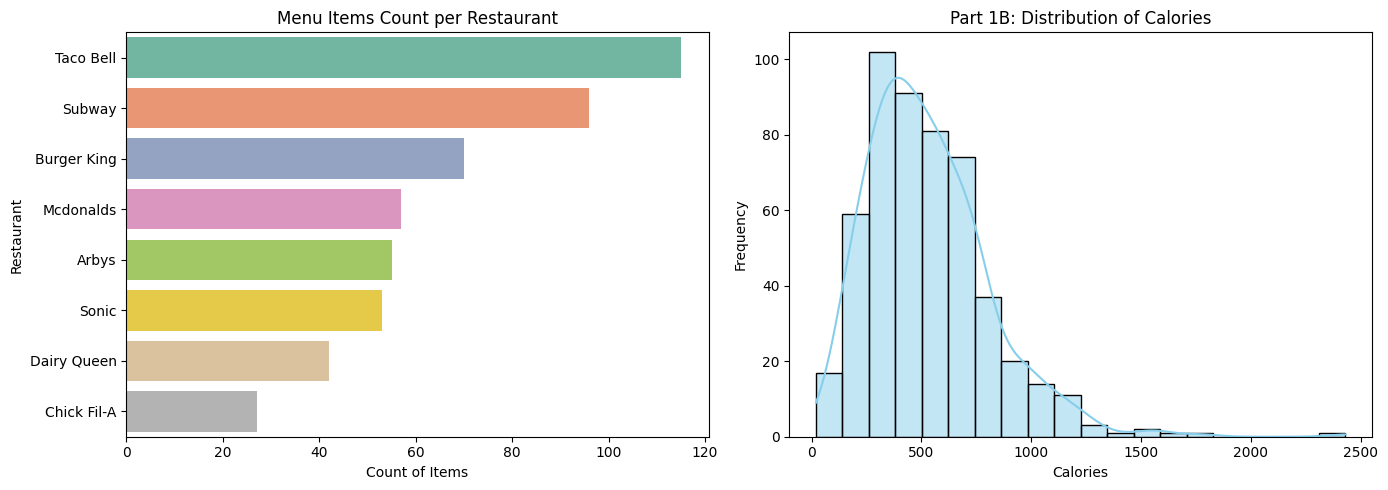

In [ ]:
# Univariate analysis (1 categorical + 1 quaantitative)

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("/content/sample_data/fastfood.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Categorical Variable: Countplot of Restaurants
sns.countplot(
    ax=axes[0],
    y="restaurant",
    data=df,
    order=df["restaurant"].value_counts().index,
    palette="Set2",
)
axes[0].set_title("Menu Items Count per Restaurant")
axes[0].set_xlabel("Count of Items")
axes[0].set_ylabel("Restaurant")

# 2. Quantitative Variable: Histogram of Calories
sns.histplot(ax=axes[1], x="calories", data=df, bins=20, kde=True, color="skyblue")
axes[1].set_title("Distribution of Calories")
axes[1].set_xlabel("Calories")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

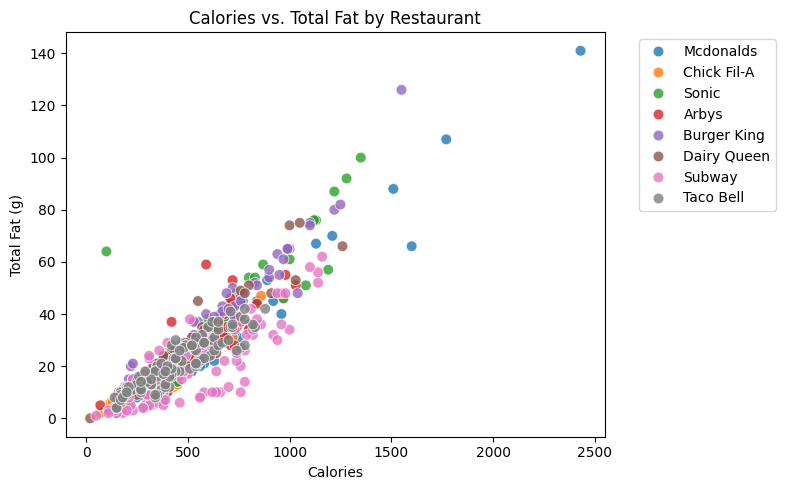

In [ ]:
# Bivariate analysis
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x="calories", y="total_fat", hue="restaurant", alpha=0.8, s=60
)
plt.title("Calories vs. Total Fat by Restaurant")
plt.xlabel("Calories")
plt.ylabel("Total Fat (g)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

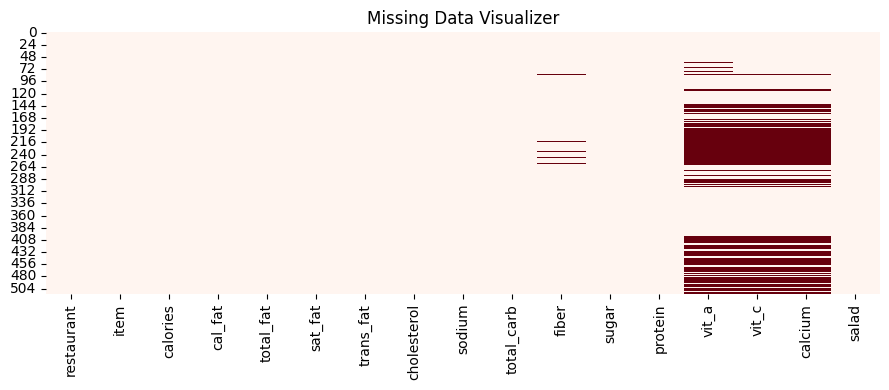

In [79]:
# Missing Data Visualization
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, cmap="Reds")
plt.title("Missing Data Visualizer")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2365/1475715596.py:6: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  months = pd.date_range(start="2024-01-01", periods=12, freq="M")


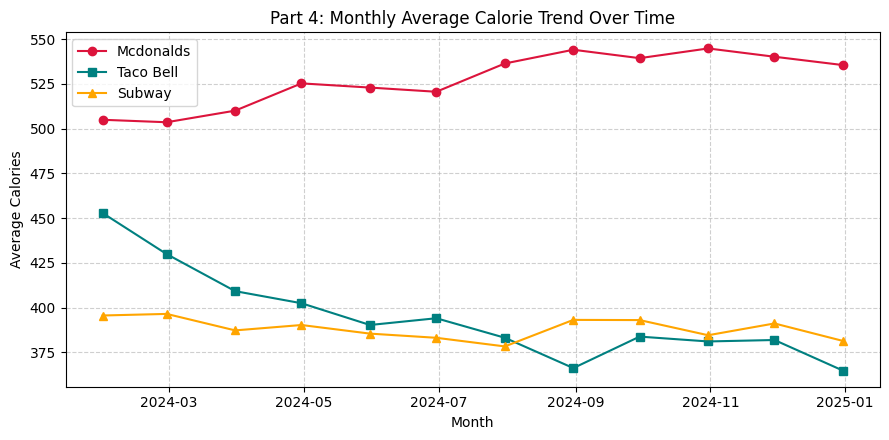

In [ ]:
# Time Series Visualization
import numpy as np

# Simulated 12-month average calorie trends
np.random.seed(42)
months = pd.date_range(start="2024-01-01", periods=12, freq="M")
mcd = 500 + np.cumsum(np.random.randn(12) * 10)
tb = 450 + np.cumsum(np.random.randn(12) * 12)
sub = 400 + np.cumsum(np.random.randn(12) * 8)

ts_df = pd.DataFrame(
    {"Month": months, "Mcdonalds": mcd, "Taco Bell": tb, "Subway": sub}
)

plt.figure(figsize=(9, 4.5))
plt.plot(
    ts_df["Month"],
    ts_df["Mcdonalds"],
    marker="o",
    label="Mcdonalds",
    color="crimson",
)
plt.plot(
    ts_df["Month"], ts_df["Taco Bell"], marker="s", label="Taco Bell", color="teal"
)
plt.plot(
    ts_df["Month"], ts_df["Subway"], marker="^", label="Subway", color="orange"
)
plt.title("Part 4: Monthly Average Calorie Trend Over Time")
plt.xlabel("Month")
plt.ylabel("Average Calories")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**6. Conclusion/Learnings/Analysis:**

<h3> In conclusion, I leanred how Exploratory data analysis allows you to thoroughly understand your data prior to making significant choices. By examining basic graphs and identifying absent information, you can quickly uncover concealed trends and rectify errors.